# Figure 12.1 — Mobility, resistivity, and Hall response

Lattice and ionized-impurity scattering set competing mobility limits. Conductivity combines carrier populations, while the Hall sign identifies the mobile charge.

## Direct NumPy calculation

The governing relations are evaluated explicitly before the reusable course implementation is imported.

300 K mobility at 1e17 cm^-3 = 191.78 cm^2/(V s)
electron Hall coefficient at 1e22 m^-3 = -6.241509e-04 m^3/C


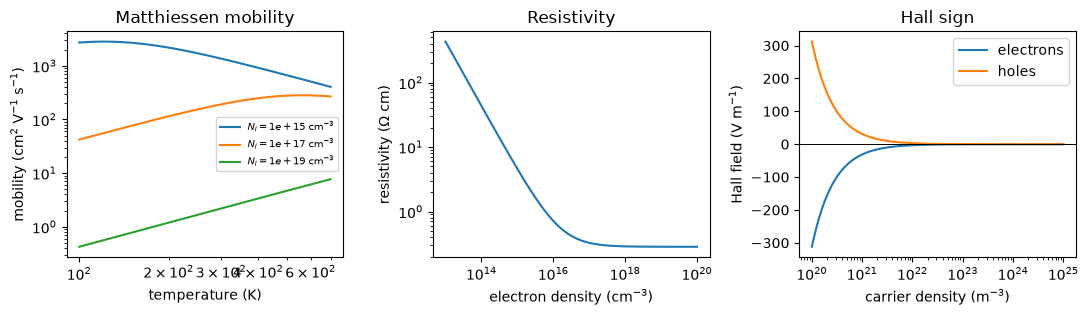

In [1]:
import numpy as np
import matplotlib.pyplot as plt

q = 1.602_176_634e-19
temperature = np.linspace(100.0, 700.0, 500)
impurity_levels = (1.0e15, 1.0e17, 1.0e19)  # cm^-3

fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.25))
for impurity in impurity_levels:
    mu_lattice = 1450.0 * (temperature / 300.0)**-1.5
    mu_impurity = 2200.0 * (temperature / 300.0)**1.5 * (1.0e16 / impurity)
    mobility = 1.0 / (1.0 / mu_lattice + 1.0 / mu_impurity)
    assert np.all(mobility < mu_lattice)
    assert np.all(mobility < mu_impurity)
    axes[0].loglog(temperature, mobility, label=fr"$N_I={impurity:.0e}$ cm$^{{-3}}$")
axes[0].set(xlabel="temperature (K)", ylabel=r"mobility (cm$^2$ V$^{-1}$ s$^{-1}$)", title="Matthiessen mobility")
axes[0].legend(fontsize=7)

density_cm3 = np.logspace(13.0, 20.0, 500)
mu_300 = 1.0 / (1.0 / 1450.0 + density_cm3 / (2200.0 * 1.0e16))
resistivity = 1.0 / (q * density_cm3 * mu_300)
axes[1].loglog(density_cm3, resistivity)
axes[1].set(xlabel=r"electron density (cm$^{-3}$)", ylabel=r"resistivity ($\Omega$ cm)", title="Resistivity")

carrier_m3 = np.logspace(20.0, 25.0, 400)
current_density, magnetic_field = 1.0e4, 0.5
for charge_sign, label in ((-1, "electrons"), (1, "holes")):
    hall_coefficient = charge_sign / (q * carrier_m3)
    hall_field = hall_coefficient * current_density * magnetic_field
    axes[2].semilogx(carrier_m3, hall_field, label=label)
axes[2].axhline(0.0, color="black", linewidth=0.7)
axes[2].set(xlabel=r"carrier density (m$^{-3}$)", ylabel=r"Hall field (V m$^{-1}$)", title="Hall sign")
axes[2].legend()

print(f"300 K mobility at 1e17 cm^-3 = {mu_300[np.argmin(abs(density_cm3-1e17))]:.2f} cm^2/(V s)")
print(f"electron Hall coefficient at 1e22 m^-3 = {-1/(q*1e22):.6e} m^3/C")
fig.tight_layout()
plt.show()

## Reusable publication implementation

The tested course implementation writes the deterministic PDF used by the manuscript.

In [2]:
import sys
from pathlib import Path

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "main.tex").exists()
)
sys.path.insert(0, str(ROOT / "figures" / "src"))

from semphy.transport_extensions import mobility_hall_figure

mobility_hall_figure()
print("wrote transport-mobility-hall.pdf")

wrote transport-mobility-hall.pdf
